# Этап 5. Прогноз вызовов на завтра (H3)

**Гипотеза H3:** модель машинного обучения предсказывает число вызовов на завтра точнее простого правила «как в такой же день недели год назад», и температура среди самых важных её признаков.

**Постановка:** вечером дня *D* прогнозируем число вызовов в каждом районе на день *D+1*. Это нужно, чтобы заранее спланировать смену бригад (этап 7, H4).

**План:**
1. Признаки: календарь, «лаги» (сколько вызовов было в прошлые дни), погода.
2. Честное разбиение **по времени**: учимся на прошлом, проверяем на будущем.
3. Базовые правила: «год назад» и «неделю назад».
4. LightGBM с погодой и без погоды.
5. Ошибки: в обычные и в жаркие дни.
6. Какие признаки важны.

*Ноутбук написал Claude. Твоя задача: прочитать, разобраться и задать вопросы.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.inspection import permutation_importance

df = (pd.read_parquet("../data/processed/daily_borough.parquet")
        .sort_values(["borough", "date"])
        .reset_index(drop=True))
df.shape

(19630, 17)

## 1. Признаки

**Лаги** — значения целевой переменной в прошлом. `shift(1)` сдвигает ряд на 1 день: в строке за 10 июня окажется число вызовов за 9 июня. Сдвигаем **внутри района** (`groupby("borough")`), чтобы Бронкс не получил вчерашние вызовы Квинса.

- `lag1` — вчера, `lag7` — неделю назад, `lag14` — две недели назад, `lag364` — год назад в тот же день недели (364 = 52 × 7);
- `roll7`, `roll28` — среднее за последние 7 и 28 дней (`shift(1)` перед `rolling`, чтобы **не подсмотреть** сам день прогноза).

**Погода.** Берём фактическую погоду дня прогноза. В реальности у нас был бы только **прогноз погоды** на завтра (ошибка ~1–2 °C), так что наша модель чуть оптимистичнее, чем была бы в работе. Это ограничение нужно честно упомянуть.

In [2]:
g = df.groupby("borough")["n_calls"]
for L in [1, 7, 14, 364]:
    df[f"lag{L}"] = g.shift(L)
df["roll7"]  = g.transform(lambda s: s.shift(1).rolling(7).mean())
df["roll28"] = g.transform(lambda s: s.shift(1).rolling(28).mean())

df["doy"]  = df["date"].dt.dayofyear                          # день года: плавная сезонность
df["heat"] = (df["temperature_2m_max"] - 10).clip(lower=0)    # градусы выше порога из этапа 4
df["borough"] = df["borough"].astype("category")              # LightGBM понимает категории сам

# COVID (03.2020–02.2022) и месяц после него выбрасываем: лаги там «отравлены» ковидными днями
covid = (df["date"] >= "2020-03-01") & (df["date"] < "2022-04-01")
df = df[~covid & df["roll28"].notna()].copy()

CAL     = ["borough", "weekday", "month", "doy", "is_holiday", "is_dst_change"]
LAGS    = ["lag1", "lag7", "lag14", "roll7", "roll28"]
WEATHER = ["temperature_2m_max", "temperature_2m_min", "apparent_temperature_max",
           "relative_humidity_2m_mean", "precipitation_sum", "heat"]
df[CAL + LAGS + WEATHER].head()

,borough,weekday,month,doy,is_holiday,is_dst_change,lag1,lag7,lag14,roll7,roll28,temperature_2m_max,temperature_2m_min,apparent_temperature_max,relative_humidity_2m_mean,precipitation_sum,heat
28,BRONX,4,1,29,False,False,940.0,906.0,933.0,967.714286,907.500000,3.5,-3.9,-1.3,73,0.1,0.0
29,BRONX,5,1,30,False,False,972.0,958.0,825.0,977.142857,905.500000,1.3,-7.3,-3.7,70,0.0,0.0
30,BRONX,6,1,31,False,False,900.0,960.0,880.0,968.857143,906.214286,5.9,-3.7,2.9,83,0.0,0.0
31,BRONX,0,2,32,False,False,835.0,1077.0,836.0,951.000000,904.535714,8.5,0.1,5.6,85,0.0,0.0
32,BRONX,1,2,33,False,False,947.0,977.0,910.0,932.428571,907.571429,8.9,-2.6,5.8,75,0.0,0.0


## 2. Разбиение по времени

Случайное разбиение (`train_test_split`) здесь **нельзя**: модель увидела бы 11 июля при обучении и «угадала» бы 10 июля на тесте. Это утечка из будущего. Поэтому:

| Часть | Период | Зачем |
|---|---|---|
| train | 2016 – 2023 (без COVID) | учим модель |
| valid | 2024 | решаем, когда остановить обучение |
| test  | 01.2025 – 09.2026 | **один раз** честно меряем качество |

In [3]:
train = df[df["date"] <  "2024-01-01"]
valid = df[(df["date"] >= "2024-01-01") & (df["date"] < "2025-01-01")]
test  = df[df["date"] >= "2025-01-01"].copy()
print(f"train {len(train)}, valid {len(valid)}, test {len(test)} строк (день × район)")
print(f"жарких дней (tmax > 30 °C) в тесте: {(test['temperature_2m_max'] > 30).sum()}")

train 10665, valid 1830, test 3190 строк (день × район)
жарких дней (tmax > 30 °C) в тесте: 363


## 3. Метрики и базовые правила

- **MAE** — средняя ошибка в вызовах: «в среднем ошибаемся на столько-то вызовов в день в районе»;
- **MAPE** — та же ошибка в % от факта. Удобно сравнивать большие и маленькие районы.

Считаем отдельно для **жарких дней** (ради них всё затевалось) и для **города целиком** (сумма 5 районов).

In [4]:
def evaluate(name, pred, data=test):
    err = (data["n_calls"] - pred).abs()
    hot = data["temperature_2m_max"] > 30
    city = (pd.DataFrame({"y": data["n_calls"], "p": pred, "date": data["date"]})
              .groupby("date").sum())
    return {"модель": name,
            "MAE": err.mean(),
            "MAPE %": (err / data["n_calls"]).mean() * 100,
            "MAPE жара %": (err[hot] / data["n_calls"][hot]).mean() * 100,
            "MAPE город %": ((city["y"] - city["p"]).abs() / city["y"]).mean() * 100}

results = [evaluate("Год назад (lag364)", test["lag364"]),
           evaluate("Неделю назад (lag7)", test["lag7"])]
pd.DataFrame(results).round(2)

,модель,MAE,MAPE %,MAPE жара %,MAPE город %
0,Год назад (lag364),56.5,7.04,7.78,4.91
1,Неделю назад (lag7),62.5,7.69,8.69,5.68


## 4. LightGBM

**LightGBM** строит много маленьких деревьев решений подряд: каждое следующее исправляет ошибки предыдущих (градиентный бустинг).

- `objective="poisson"` — та же идея, что в этапе 4: число вызовов — это счётчик;
- `early_stopping(100)` — добавляем деревья, пока ошибка на **valid** падает; если 100 деревьев подряд не помогли, стоп. Это защита от переобучения.

Обучаем **две** модели: с погодой и без. Разница между ними и есть ответ «нужна ли температура».

In [5]:
def train_lgbm(features):
    model = lgb.LGBMRegressor(objective="poisson", n_estimators=3000, learning_rate=0.03,
                              num_leaves=31, min_child_samples=30,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              random_state=42, verbose=-1)
    model.fit(train[features], train["n_calls"],
              eval_X=(valid[features],), eval_y=(valid["n_calls"],),
              callbacks=[lgb.early_stopping(100, verbose=False)])
    print(f"  {len(features)} признаков, деревьев: {model.best_iteration_}")
    return model

FEATS_FULL = CAL + LAGS + WEATHER
FEATS_NOW  = CAL + LAGS

m_full = train_lgbm(FEATS_FULL)
m_now  = train_lgbm(FEATS_NOW)

test["pred"]    = m_full.predict(test[FEATS_FULL])
test["pred_nw"] = m_now.predict(test[FEATS_NOW])

results += [evaluate("LightGBM без погоды", test["pred_nw"]),
            evaluate("LightGBM с погодой",  test["pred"])]
res = pd.DataFrame(results).round(2)
res

  17 признаков, деревьев: 1092


  11 признаков, деревьев: 698


,модель,MAE,MAPE %,MAPE жара %,MAPE город %
0,Год назад (lag364),56.50,7.04,7.78,4.91
1,Неделю назад (lag7),62.50,7.69,8.69,5.68
2,LightGBM без погоды,41.41,5.16,5.84,3.46
3,LightGBM с погодой,36.72,4.68,5.04,2.72


In [6]:
base = res.set_index("модель").loc["Год назад (lag364)"]
best = res.set_index("модель").loc["LightGBM с погодой"]
nowx = res.set_index("модель").loc["LightGBM без погоды"]
for col in ["MAPE %", "MAPE жара %", "MAPE город %"]:
    print(f"{col:14s}: ML лучше правила «год назад» на {(1 - best[col]/base[col])*100:.0f} %, "
          f"погода снижает ошибку ещё на {(1 - best[col]/nowx[col])*100:.0f} %")

MAPE %        : ML лучше правила «год назад» на 34 %, погода снижает ошибку ещё на 9 %
MAPE жара %   : ML лучше правила «год назад» на 35 %, погода снижает ошибку ещё на 14 %
MAPE город %  : ML лучше правила «год назад» на 45 %, погода снижает ошибку ещё на 21 %


## 5. Как это выглядит: лето 2025, город целиком

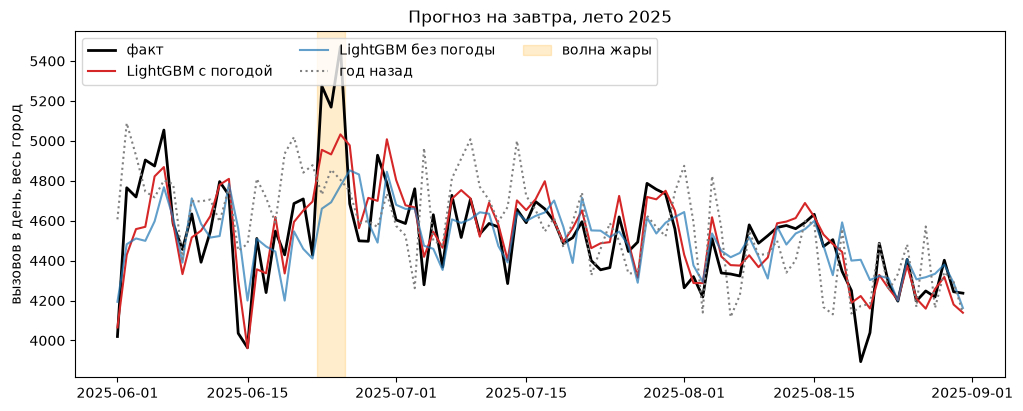

,n_calls,pred,pred_nw,lag364
date,,,,
2025-06-21,4709,4651.0,4459.0,4841.0
2025-06-22,4428,4696.0,4411.0,4878.0
2025-06-23,5275,4955.0,4660.0,4731.0
2025-06-24,5169,4932.0,4692.0,4856.0
2025-06-25,5472,5032.0,4774.0,4805.0
2025-06-26,4685,4978.0,4852.0,4748.0
2025-06-27,4499,4563.0,4832.0,4587.0


In [7]:
city = (test.groupby("date")[["n_calls", "pred", "pred_nw", "lag364", "temperature_2m_max"]]
            .agg({"n_calls": "sum", "pred": "sum", "pred_nw": "sum", "lag364": "sum", "temperature_2m_max": "mean"}))
summer = city.loc["2025-06-01":"2025-08-31"]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(summer.index, summer["n_calls"], color="black", linewidth=2, label="факт")
ax.plot(summer.index, summer["pred"],    color="tab:red",  label="LightGBM с погодой")
ax.plot(summer.index, summer["pred_nw"], color="tab:blue", alpha=0.7, label="LightGBM без погоды")
ax.plot(summer.index, summer["lag364"],  color="grey", linestyle=":", label="год назад")
ax.axvspan(pd.Timestamp("2025-06-22 12:00"), pd.Timestamp("2025-06-25 12:00"), color="orange", alpha=0.2, label="волна жары")
ax.set_ylabel("вызовов в день, весь город"); ax.legend(ncol=3, loc="upper left")
ax.set_title("Прогноз на завтра, лето 2025")
plt.show()

summer.loc["2025-06-21":"2025-06-27", ["n_calls", "pred", "pred_nw", "lag364"]].round(0)

## 6. Какие признаки важны?

**Permutation importance:** берём тестовые данные, перемешиваем **один** столбец (например, температуру), и смотрим, насколько выросла ошибка. Если модель от этого признака зависит, ошибка сильно вырастет; если нет, почти не изменится. Признак `borough` будет на первом месте почти при любом методе: он задаёт **уровень** района (в Бруклине вызовов в 5 раз больше, чем на Статен-Айленде). Интереснее, что идёт после него.

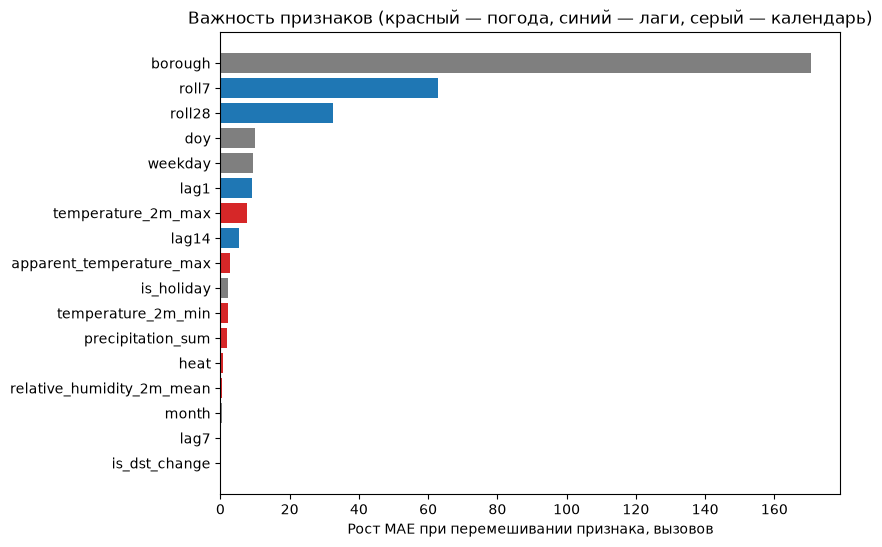

borough               170.55
roll7                  62.97
roll28                 32.63
doy                     9.87
weekday                 9.37
lag1                    9.01
temperature_2m_max      7.70
lag14                   5.44
dtype: float64

In [8]:
perm = permutation_importance(m_full, test[FEATS_FULL], test["n_calls"],
                              scoring="neg_mean_absolute_error", n_repeats=5, random_state=42)
imp = pd.Series(perm.importances_mean, index=FEATS_FULL).sort_values()
group = {**{f: "календарь" for f in CAL}, **{f: "лаги" for f in LAGS}, **{f: "погода" for f in WEATHER}}
colors = [{"календарь": "tab:grey", "лаги": "tab:blue", "погода": "tab:red"}[group[f]] for f in imp.index]

plt.figure(figsize=(8, 6))
plt.barh(imp.index, imp.values, color=colors)
plt.xlabel("Рост MAE при перемешивании признака, вызовов")
plt.title("Важность признаков (красный — погода, синий — лаги, серый — календарь)")
plt.show()
imp.sort_values(ascending=False).round(2).head(8)

## Итоги: подтвердилась ли H3?

**Ответ (черновик Claude, перепиши своими словами):**
1. **ML точнее простого правила — да.** На тесте (01.2025–09.2026) LightGBM ошибается на **4,7 %** в день по району против **7,0 %** у правила «год назад»: ошибка меньше на треть. По городу целиком **2,7 % против 4,9 %** (почти вдвое).
2. **Погода полезна, особенно в жару.** Без погоды ошибка в жаркие дни 5,8 %, с погодой 5,0 % (−14 %); по городу −21 %. В волну жары 23–25.06.2025 модель без погоды недооценила вызовы на ~600–700 в день и потом «догоняла» с опозданием, когда жара уже спала.
3. **Температура среди важных признаков — частично.** `temperature_2m_max` — самый важный погодный признак и входит в топ-8, но впереди район (уровень), недавние лаги (`roll7`, `roll28`, `lag1`) и календарь. Главный предсказатель завтрашних вызовов — сколько их было на этой неделе; погода объясняет **отклонения** от этого уровня.
4. **Ограничение:** мы брали фактическую погоду, а в работе был бы прогноз погоды (ошибка ~1–2 °C), так что реальная точность будет немного хуже.

**Строка для README:** *Прогноз вызовов на завтра на LightGBM: MAPE 4,7 % по району и 2,7 % по городу против 7,0 % / 4,9 % у сезонного правила «год назад»; погодные признаки снижают ошибку в жаркие дни на 14 %.*

Дальше (этап 6): SHAP — как именно температура меняет прогноз, и совпадает ли это с порогом 10 °C из этапа 4.